In [11]:
import torch
from torch import nn
import torchvision
import matplotlib.pyplot as plt 

from torchvision import transforms
from torchinfo import summary
from Going_modular import data_setup, engine

In [12]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [13]:
import torchvision
torchvision.__version__

'0.29.0+cu130'

In [14]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [15]:
torchvision.__version__

'0.29.0+cu130'

In [16]:
# Setup directory path
from pathlib import Path

data_path = Path("data")
image_path = data_path/ "applepie_fries_icecream_20_percent"

In [17]:
train_dir = image_path / "train"
test_dir = image_path / "test"

train_dir, test_dir

(WindowsPath('data/applepie_fries_icecream_20_percent/train'),
 WindowsPath('data/applepie_fries_icecream_20_percent/test'))

## 1. Turn our images into Datasets and Dataloaders
### To do this we could use the **`data_setup.py`** and **`create_dataloaders()`** function from 05. PyTorch Going Modular.
### How do we **transform** our data? Well we have torchvision `0.14+` there are two ways to do this:
* **Manually created transforms - you define what transforms you want your data to have**
* **Automatically created transforms - the transforms for your data are defined by the model you would like to use**
### Important point : when using a pre-trained model it is important that the data including your custom data that you pass through, it is **transformed** in the same way as the pre-trained data model was trained on.

In [18]:
train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders()

TypeError: create_dataloaders() missing 5 required positional arguments: 'train_dir', 'test_dir', 'transform', 'batch_size', and 'num_workers'

### 1.1 Creating a transform for `torchvision.models` (manual creation)

In [19]:
normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406],  # this values were from the earlier version of torchvision but the latest version doesn't have these values 
                                std=[0.229, 0.224, 0.225])
manual_transforms = transforms.Compose([transforms.Resize((224,224)),
                                       transforms.ToTensor(),  
                                       normalize])

In [20]:
train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(train_dir=train_dir,
                                                                              test_dir=test_dir,
                                                                              transform=manual_transforms,
                                                                              batch_size=32,
                                                                              num_workers=4)

In [21]:
train_dataloader, test_dataloader, class_names

(<torch.utils.data.dataloader.DataLoader at 0x27b8970eba0>,
 ['apple_pie', 'french_fries', 'ice_cream'])

### 1.2 Creating a transform for `torchvision.models` the latest version of torchvision `0.14+` (auto creation)
#### **As we are using `0.29` there is now support for automatic data transform creation based on pretrained model weights that we will be using.**
#### Alot of info - https://docs.pytorch.org/vision/stable/models.html

In [22]:
# Get a set of pretrained weights
weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
weights

EfficientNet_B0_Weights.IMAGENET1K_V1

### Before using the pre-trained models, one must preprocess the image (resize with right resolution/interpolation, apply inference transforms, rescale the values etc). There is no standard way to do this as it depends on how a given model was trained. It can vary across model families, variants or even weight versions. Using the correct preprocessing method is critical and failing to do so may lead to decreased accuracy or incorrect outputs.

In [23]:
# Get the transforms used to create our pre-trained weights 
auto_transforms = weights.transforms()
auto_transforms

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)

In [24]:
# Create dataloaders using auto transform
train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(train_dir=train_dir,
                                                                              test_dir=test_dir,
                                                                              transform=auto_transforms,
                                                                              batch_size=32,
                                                                              num_workers=4)
train_dataloader, test_dataloader, class_names

(<torch.utils.data.dataloader.DataLoader at 0x27b8971e850>,
 ['apple_pie', 'french_fries', 'ice_cream'])

## 2. Getting a pretrained model 
### There are various places to get a pre-trained model such as:
* **PyTorch Domain Libararies**
* **Libraries like `timm` (torch image models)**
* **HuggingFace Hub (for plenty of different models)**

### 2.1 Which pretrained model should you use?
#### It is just experiment, experiment depending on your data and use case.
#### Three things to consider:
* **Speed** - how fast does it run?
* **Size** - how big is the model ?
* **Performance** - how well does the model do on your custom data or chosen problem

### 2.2 Setting up a pretrained model 
#### Want to create an instance of a pretrained EfficientNet - https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.efficientnet_b0.html#torchvision.models.EfficientNet_B0_Weights

In [25]:
weights

EfficientNet_B0_Weights.IMAGENET1K_V1

In [26]:
model = torchvision.models.efficientnet_b0(weights=weights).to(device)
model

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          

### 2.3 Getting summary of torchinfo

In [27]:
summary(model=model, input_size=(1,3,224,224),   # batch, color channel, height and width
        col_names=["input_size","output_size", "num_params", "trainable"],
       col_width=20,
       row_settings=["var_names"])   

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [1, 3, 224, 224]     [1, 1000]            --                   True
├─Sequential (features)                                      [1, 3, 224, 224]     [1, 1280, 7, 7]      --                   True
│    └─Conv2dNormActivation (0)                              [1, 3, 224, 224]     [1, 32, 112, 112]    --                   True
│    │    └─Conv2d (0)                                       [1, 3, 224, 224]     [1, 32, 112, 112]    864                  True
│    │    └─BatchNorm2d (1)                                  [1, 32, 112, 112]    [1, 32, 112, 112]    64                   True
│    │    └─SiLU (2)                                         [1, 32, 112, 112]    [1, 32, 112, 112]    --                   --
│    └─Sequential (1)                                        [1, 32, 112, 112]    [1, 16, 112,

### 2.4 Freezing the base model and changing the output layer to suit our needs 

In [28]:
# Freeze all of the base layer in effnetb0
for param in model.features.parameters():
    param.requires_grad = False

In [29]:
# update the classifier head to our model to suit our problem
torch.manual_seed(21)
torch.cuda.manual_seed(21)
model.classifier = nn.Sequential(nn.Dropout(p=0.2,inplace=True),
                                nn.Linear(in_features=1280, out_features=len(class_names))).to(device)
model.classifier

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=3, bias=True)
)

In [30]:
summary(model=model, input_size=(1,3,224,224),   # batch, color channel, height and width
        col_names=["input_size","output_size", "num_params", "trainable"],
       col_width=20,
       row_settings=["var_names"])  

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [1, 3, 224, 224]     [1, 3]               --                   Partial
├─Sequential (features)                                      [1, 3, 224, 224]     [1, 1280, 7, 7]      --                   False
│    └─Conv2dNormActivation (0)                              [1, 3, 224, 224]     [1, 32, 112, 112]    --                   False
│    │    └─Conv2d (0)                                       [1, 3, 224, 224]     [1, 32, 112, 112]    (864)                False
│    │    └─BatchNorm2d (1)                                  [1, 32, 112, 112]    [1, 32, 112, 112]    (64)                 False
│    │    └─SiLU (2)                                         [1, 32, 112, 112]    [1, 32, 112, 112]    --                   --
│    └─Sequential (1)                                        [1, 32, 112, 112]    [1, 1

## 3. Train model

In [31]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model.parameters(), lr=0.001)

In [32]:
#Import train function 
from Going_modular import engine

torch.manual_seed(21)
torch.cuda.manual_seed(21)

results = engine.train(model=model,
                      train_dataloader=train_dataloader,
                      test_dataloader=test_dataloader,
                      optimizer=optimizer,
                      loss_fn=loss_fn,
                      epochs=20,
                      device=device)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 0.9102 | train_acc: 0.6257 | test_loss: 0.7243 | test_acc: 0.7977
Epoch: 2 | train_loss: 0.6803 | train_acc: 0.8049 | test_loss: 0.6256 | test_acc: 0.7739
Epoch: 3 | train_loss: 0.5705 | train_acc: 0.8403 | test_loss: 0.5828 | test_acc: 0.7801
Epoch: 4 | train_loss: 0.4849 | train_acc: 0.8708 | test_loss: 0.5307 | test_acc: 0.7773
Epoch: 5 | train_loss: 0.4180 | train_acc: 0.9042 | test_loss: 0.5060 | test_acc: 0.8080
Epoch: 6 | train_loss: 0.4116 | train_acc: 0.8757 | test_loss: 0.4715 | test_acc: 0.8108
Epoch: 7 | train_loss: 0.3726 | train_acc: 0.9083 | test_loss: 0.4599 | test_acc: 0.8358
Epoch: 8 | train_loss: 0.3981 | train_acc: 0.8556 | test_loss: 0.4333 | test_acc: 0.8443
Epoch: 9 | train_loss: 0.3242 | train_acc: 0.9313 | test_loss: 0.4411 | test_acc: 0.8426
Epoch: 10 | train_loss: 0.3330 | train_acc: 0.9125 | test_loss: 0.4271 | test_acc: 0.8545
Epoch: 11 | train_loss: 0.2958 | train_acc: 0.9271 | test_loss: 0.4168 | test_acc: 0.8455
Epoch: 12 | train_l

## 4. Evaluate the model by plotting loss curves

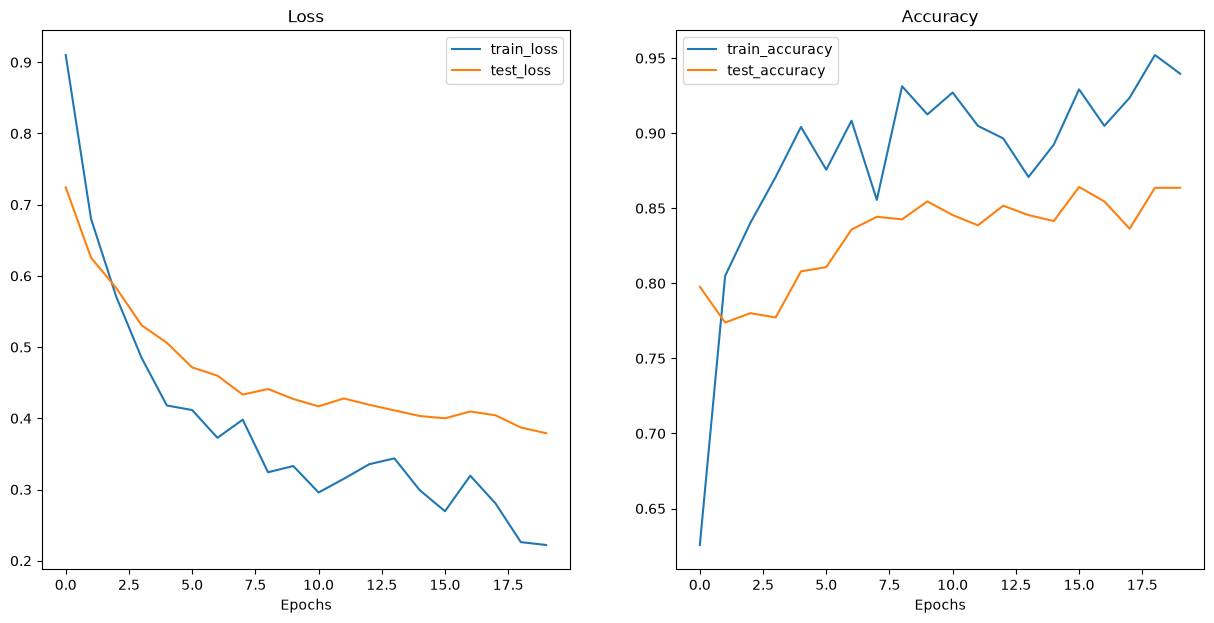

In [33]:
from helper_functions import plot_loss_curves
#plot the loss curves
plot_loss_curves(results)

## 5. Make predictions on images from the test set
### Let's adhere to the data explorer motto that is vizualize, vizualize.
### Some things to keep in mind when making prediction/inference on test data that are :
1. **Same shape - images need to be of same shape as model was trained on**
2. **Same datatype - custom data should be in same datatype**
3. **Same device - custom data/test data should be on the same device as model data was trained on**
4. **Same transform - if you have transformed your train data ideally you will transform the test data and custom data the same** 

In [42]:
from PIL import Image

# 1. Take in a trained model, class names, image path, image size, a transform and target device
def pred_and_plot_image(model,
                        image_path, 
                        class_names,
                        image_size=(224,224),
                        transform=None,
                        device=device):
    
    
    # 2. Open image
    img = Image.open(image_path)

    # 3. Create transformation for image (if one doesn't exist)
    if transform is not None:
        image_transform = transform
    else:
        image_transform = transforms.Compose([
            transforms.Resize(image_size),
            transforms.ToTensor(),
            transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                 std=[0.229, 0.224, 0.225]),
        ])

    ### Predict on image ### 

    # 4. Make sure the model is on the target device
    model.to(device)

    # 5. Turn on model evaluation mode and inference mode
    model.eval()
    with torch.inference_mode():
      # 6. Transform and add an extra dimension to image (model requires samples in [batch_size, color_channels, height, width])
      transformed_image = image_transform(img).unsqueeze(dim=0)

      # 7. Make a prediction on image with an extra dimension and send it to the target device
      target_image_pred = model(transformed_image.to(device))

    # 8. Convert logits -> prediction probabilities (using torch.softmax() for multi-class classification)
    target_image_pred_probs = torch.softmax(target_image_pred, dim=1)

    # 9. Convert prediction probabilities -> prediction labels
    target_image_pred_label = torch.argmax(target_image_pred_probs, dim=1)

    # 10. Plot image with predicted label and probability 
    plt.figure()
    plt.imshow(img)
    plt.title(f"Pred: {class_names[target_image_pred_label]} | Prob: {target_image_pred_probs.max():.3f}")
    plt.axis(False);

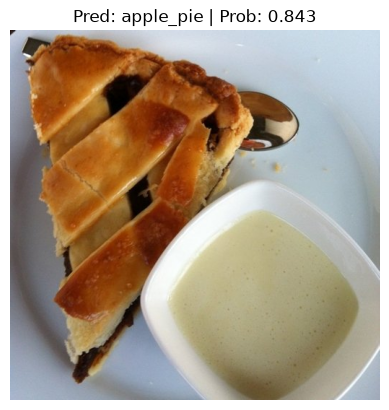

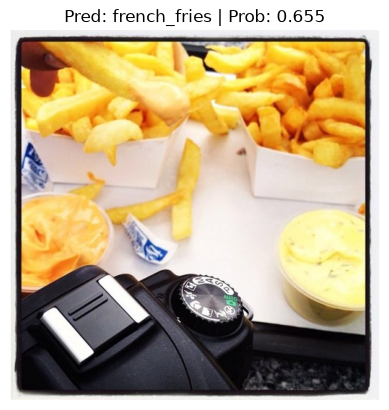

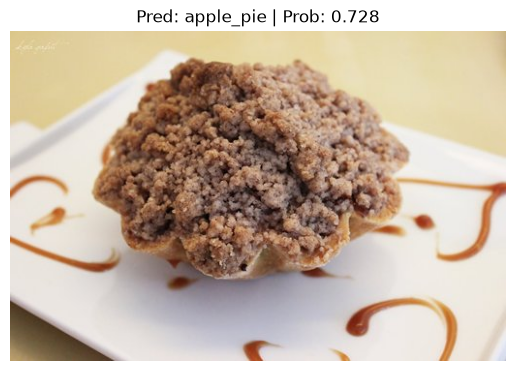

In [43]:
# Get a random list of image paths from test set
import random
num_images_to_plot = 3
test_image_path_list = list(Path(test_dir).glob("*/*.jpg")) # get list all image paths from test data 
test_image_path_sample = random.sample(population=test_image_path_list, # go through all of the test image paths
                                       k=num_images_to_plot) # randomly select 'k' image paths to pred and plot

# Make predictions on and plot the images
for image_path in test_image_path_sample:
    pred_and_plot_image(model=model, 
                        image_path=image_path,
                        class_names=class_names,
                        # transform=weights.transforms(), # optionally pass in a specified transform from our pretrained model weights
                        image_size=(224, 224))